# DEPENDENCIES

In [14]:
!pip install opencv-python matplotlib scikit-learn scipy
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121
!pip install torch torchvision


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Looking in indexes: https://download.pytorch.org/whl/cu121



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# IMPORT

In [15]:
import os
import cv2
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import torchvision.transforms.functional as TF

from scipy.ndimage import gaussian_filter, map_coordinates

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


# PATHS

In [16]:
train_image_dir = "../dataset/DRIVE/training/images"
train_mask_dir = "../dataset/DRIVE/training/1st_manual"

test_image_dir = "../dataset/DRIVE/test/images"
test_mask_dir = "../dataset/DRIVE/test/1st_manual"

# DATASET CLASS

In [17]:
def elastic_transform(image, mask, alpha=34, sigma=4):

    image = np.array(image)
    mask = np.array(mask)

    shape = image.shape[:2]

    dx = gaussian_filter((np.random.rand(*shape) * 2 - 1), sigma) * alpha
    dy = gaussian_filter((np.random.rand(*shape) * 2 - 1), sigma) * alpha

    x, y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))

    indices = (y + dy, x + dx)

    deformed_img = np.zeros_like(image)

    for i in range(3):
        deformed_img[:,:,i] = map_coordinates(
            image[:,:,i], indices, order=1, mode='reflect'
        )

    deformed_mask = map_coordinates(
        mask, indices, order=0, mode='nearest'
    )
    

    return Image.fromarray(deformed_img), Image.fromarray(deformed_mask)

class DriveDataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.images = sorted(os.listdir(image_dir))

        self.transform = transforms.Compose([
            transforms.Resize((256,256)),
            transforms.ToTensor(),
            transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])
        ])

        self.mask_transform = transforms.Compose([
            transforms.Resize((256,256), interpolation=InterpolationMode.NEAREST),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        img_name = self.images[idx]
        img_path = os.path.join(self.image_dir, img_name)

        number = img_name.split("_")[0]
        mask_name = number + "_manual1.gif"
        mask_path = os.path.join(self.mask_dir, mask_name)

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, 0)

        if image is None:
            raise ValueError(f"Image not found: {img_path}")
        if mask is None:
            raise ValueError(f"Mask not found: {mask_path}")

        image = Image.fromarray(image)
        mask = Image.fromarray(mask)

        if random.random() > 0.5:
            image, mask = elastic_transform(image, mask)

        if random.random() > 0.5:
            angle = random.uniform(-20,20)
            image = TF.rotate(image, angle)
            mask = TF.rotate(mask, angle, interpolation=InterpolationMode.NEAREST)

        if random.random() > 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)

        if random.random() > 0.5:
            image = TF.vflip(image)
            mask = TF.vflip(mask)

        image = self.transform(image)
        mask = self.mask_transform(mask)

        mask = (mask > 0).float()

        return image, mask

# LOAD DATASET

In [ ]:
train_dataset = DriveDataset(train_image_dir, train_mask_dir)
train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True)

print("Training images:", len(train_dataset))

Training images: 20


# VISUALIZE SAMPLE

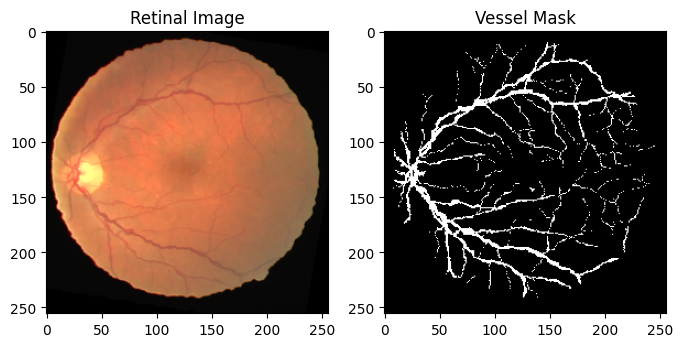

In [19]:
image, mask = train_dataset[0]

plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.title("Retinal Image")
plt.imshow(image.permute(1,2,0)*0.5 + 0.5)

plt.subplot(1,2,2)
plt.title("Vessel Mask")
plt.imshow(mask.squeeze(), cmap="gray")

plt.show()

# U-NET MODEL

In [ ]:
class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels,out_channels,3,padding=0),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.1),
            nn.Conv2d(out_channels,out_channels,3,padding=0),
            nn.ReLU(inplace=True)
        )

    def forward(self,x):
        return self.conv(x)


class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.down1 = DoubleConv(3,64)
        self.down2 = DoubleConv(64,128)
        self.down3 = DoubleConv(128,256)

        self.pool = nn.MaxPool2d(2)

        self.middle = DoubleConv(256,512)

        self.up3 = nn.ConvTranspose2d(512,256,2,stride=2)
        self.conv3 = DoubleConv(512,256)

        self.up2 = nn.ConvTranspose2d(256,128,2,stride=2)
        self.conv2 = DoubleConv(256,128)

        self.up1 = nn.ConvTranspose2d(128,64,2,stride=2)
        self.conv1 = DoubleConv(128,64)

        self.out = nn.Conv2d(64,1,1)

    def forward(self,x):

        d1 = self.down1(x)
        p1 = self.pool(d1)

        d2 = self.down2(p1)
        p2 = self.pool(d2)

        d3 = self.down3(p2)
        p3 = self.pool(d3)

        m = self.middle(p3)

        u3 = self.up3(m)
        u3 = torch.cat([u3,d3],dim=1)
        u3 = self.conv3(u3)

        u2 = self.up2(u3)
        u2 = torch.cat([u2,d2],dim=1)
        u2 = self.conv2(u2)

        u1 = self.up1(u2)
        u1 = torch.cat([u1,d1],dim=1)
        u1 = self.conv1(u1)

        return self.out(u1)

# INITIALIZE MODEL

In [ ]:
model = UNet().to(device)

optimizer = optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.99,
    weight_decay=1e-5
)

print(model)

UNet(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Dropout2d(p=0.1, inplace=False)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU(inplace=True)
    )
  )
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Dropout2d(p=0.1, inplace=False)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU(inplace=True)
    )
  )
  (down3): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Dropout2d(p=0.1, inplace=False)
      (3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU(inplace=True)
    )
  )
  (pool): MaxPool2d(kernel_size=2, stride=2, p

# LOSS FUNCTIONS

In [22]:
bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([5.0]).to(device))

# TRAINING LOOP

In [23]:
epochs = 300

start_training = time.time()

for epoch in range(epochs):

    epoch_start = time.time()

    model.train()

    epoch_loss = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        preds = model(images)

        loss = bce(preds, masks)

        preds_prob = torch.sigmoid(preds)
        preds_bin = (preds_prob.detach() > 0.5).float()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {epoch_loss/len(train_loader):.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

total_time = time.time() - start_training
print(f"\nTotal training time: {total_time/60:.2f} minutes")

Epoch 1/300 | Loss: 0.9164 | Time: 14.67s
Epoch 2/300 | Loss: 0.9034 | Time: 15.86s
Epoch 3/300 | Loss: 0.8859 | Time: 10.75s
Epoch 4/300 | Loss: 0.8694 | Time: 11.40s
Epoch 5/300 | Loss: 0.8528 | Time: 12.16s
Epoch 6/300 | Loss: 0.8326 | Time: 12.27s
Epoch 7/300 | Loss: 0.8125 | Time: 12.55s
Epoch 8/300 | Loss: 0.7929 | Time: 12.76s
Epoch 9/300 | Loss: 0.7795 | Time: 12.38s
Epoch 10/300 | Loss: 0.7567 | Time: 14.35s
Epoch 11/300 | Loss: 0.7423 | Time: 15.08s
Epoch 12/300 | Loss: 0.7335 | Time: 11.59s
Epoch 13/300 | Loss: 0.7239 | Time: 10.21s
Epoch 14/300 | Loss: 0.7188 | Time: 9.98s
Epoch 15/300 | Loss: 0.7091 | Time: 9.98s
Epoch 16/300 | Loss: 0.7139 | Time: 10.12s
Epoch 17/300 | Loss: 0.7058 | Time: 10.01s
Epoch 18/300 | Loss: 0.7059 | Time: 9.86s
Epoch 19/300 | Loss: 0.7054 | Time: 10.08s
Epoch 20/300 | Loss: 0.7027 | Time: 10.12s
Epoch 21/300 | Loss: 0.7053 | Time: 10.13s
Epoch 22/300 | Loss: 0.7014 | Time: 10.02s
Epoch 23/300 | Loss: 0.7050 | Time: 9.91s
Epoch 24/300 | Loss: 0.7

# PREDICTION

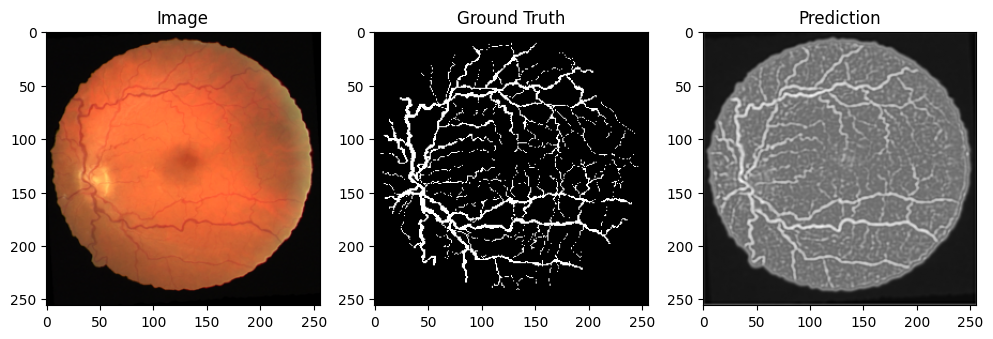

In [24]:
model.eval()

image, mask = train_dataset[1]

with torch.no_grad():

    pred = model(image.unsqueeze(0).to(device))
    pred = pred.squeeze().cpu().numpy()

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Image")
plt.imshow(image.permute(1,2,0)*0.5 + 0.5)

plt.subplot(1,3,2)
plt.title("Ground Truth")
plt.imshow(mask.squeeze(), cmap="gray")

plt.subplot(1,3,3)
plt.title("Prediction")
plt.imshow(pred, cmap="gray")

plt.show()

# SAVE MODEL

In [25]:
torch.save(model.state_dict(), "unet_drive.pth")